# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Computer Vision Lab — Google Colab notebook template**

This notebook follows the uploaded exam brief. It compares HOG + LinearSVC with fixed-grid SIFT + LinearSVC on four BloodMNIST classes, then evaluates clean, rotated, and noisy test images.

**Before running:** enter your registration number below. The notebook uses its last two digits as the random seed, last digit parity for HOG cell size, and last digit range for the SIFT grid. All reported results must come from the executed outputs; do not invent or fill in metrics manually.

**Important:** Q4 is the only section that evaluates the test set. Model selection uses validation data only.


## Registration settings
Edit `REGISTRATION_NUMBER` in the next cell. Use the digits only, including any leading zero if your roll number has one (e.g. `"064"`).

In [11]:
# EDIT THIS
REGISTRATION_NUMBER = "059"  # <-- replace with your own registration/roll number

digits = "".join(ch for ch in REGISTRATION_NUMBER if ch.isdigit())
if len(digits) < 2:
    raise ValueError("Enter a registration number containing at least two digits.")

SEED = int(digits[-2:])
last_digit = int(digits[-1])
HOG_CELL_SIZE = (8, 8) if last_digit % 2 == 0 else (16, 16)
SIFT_GRID_SIZE = 4 if last_digit <= 4 else 6

print("Seed:", SEED)
print("HOG cell size:", HOG_CELL_SIZE)
print(f"SIFT grid: {SIFT_GRID_SIZE} x {SIFT_GRID_SIZE} = {SIFT_GRID_SIZE**2} keypoints")

Seed: 59
HOG cell size: (16, 16)
SIFT grid: 6 x 6 = 36 keypoints


## Setup: install packages
Run this cell once in Google Colab. If imports fail after installation, restart the runtime and run the notebook again from the top.

In [12]:
%pip -q install medmnist opencv-python-headless scikit-image scikit-learn matplotlib pandas

In [13]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import medmnist
from medmnist import INFO
from skimage.feature import hog
from skimage.transform import rotate, resize
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")
random.seed(SEED)
np.random.seed(SEED)
cv2.setRNGSeed(SEED)

print("OpenCV:", cv2.__version__)
print("MedMNIST:", medmnist.__version__)

OpenCV: 5.0.0
MedMNIST: 3.0.2


## Q1. Data setup (3 marks)
Use BloodMNIST at size 64, keeping classes eosinophil (1), monocyte (5), neutrophil (6), and platelet (7). The exam specifies 100 train, 30 validation, and 30 test images per class, selected with your seed. Images are converted to grayscale and resized to 128 × 128.

In [14]:
# Download/load official BloodMNIST splits
DATA_FLAG = "bloodmnist"
info = INFO[DATA_FLAG]
DataClass = getattr(medmnist, info["python_class"])
train_ds = DataClass(split="train", download=True, size=64)
val_ds   = DataClass(split="val", download=True, size=64)
test_ds  = DataClass(split="test", download=True, size=64)

CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = {1: "eosinophil", 5: "monocyte", 6: "neutrophil", 7: "platelet"}
IMG_SIZE = 128

def unpack_dataset(ds):
    imgs = np.asarray(ds.imgs)
    labels = np.asarray(ds.labels).reshape(-1).astype(int)
    return imgs, labels

raw_train_x, raw_train_y = unpack_dataset(train_ds)
raw_val_x, raw_val_y = unpack_dataset(val_ds)
raw_test_x, raw_test_y = unpack_dataset(test_ds)

def prepare_split(images, labels, per_class, seed):
    rng = np.random.default_rng(seed)
    chosen_images, chosen_labels = [], []
    for class_id in CLASS_IDS:
        indices = np.flatnonzero(labels == class_id)
        if len(indices) < per_class:
            raise ValueError(f"Class {class_id} only has {len(indices)} items; need {per_class}.")
        selected = rng.choice(indices, size=per_class, replace=False)
        chosen_images.extend(images[selected])
        chosen_labels.extend([class_id] * per_class)
    order = rng.permutation(len(chosen_labels))
    return np.asarray(chosen_images)[order], np.asarray(chosen_labels, dtype=int)[order]

train_x_raw, train_y = prepare_split(raw_train_x, raw_train_y, 100, SEED)
val_x_raw, val_y = prepare_split(raw_val_x, raw_val_y, 30, SEED + 1)
test_x_raw, test_y = prepare_split(raw_test_x, raw_test_y, 30, SEED + 2)

def to_gray128(image):
    image = np.asarray(image)
    if image.ndim == 2:
        gray = image
    elif image.shape[-1] == 1:
        gray = image[..., 0]
    else:
        gray = cv2.cvtColor(image.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray.astype(np.uint8), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC)
    return gray

train_gray = np.stack([to_gray128(im) for im in train_x_raw])
val_gray = np.stack([to_gray128(im) for im in val_x_raw])
test_gray = np.stack([to_gray128(im) for im in test_x_raw])

def split_summary(name, x, y):
    print(f"{name}: images shape = {x.shape}, labels shape = {y.shape}")
    print(pd.Series([CLASS_NAMES[int(v)] for v in y]).value_counts().reindex(
        [CLASS_NAMES[c] for c in CLASS_IDS], fill_value=0).to_string())

split_summary("Train", train_gray, train_y)
print()
split_summary("Validation", val_gray, val_y)
print()
split_summary("Test", test_gray, test_y)

Train: images shape = (400, 128, 128), labels shape = (400,)
eosinophil    100
monocyte      100
neutrophil    100
platelet      100

Validation: images shape = (120, 128, 128), labels shape = (120,)
eosinophil    30
monocyte      30
neutrophil    30
platelet      30

Test: images shape = (120, 128, 128), labels shape = (120,)
eosinophil    30
monocyte      30
neutrophil    30
platelet      30


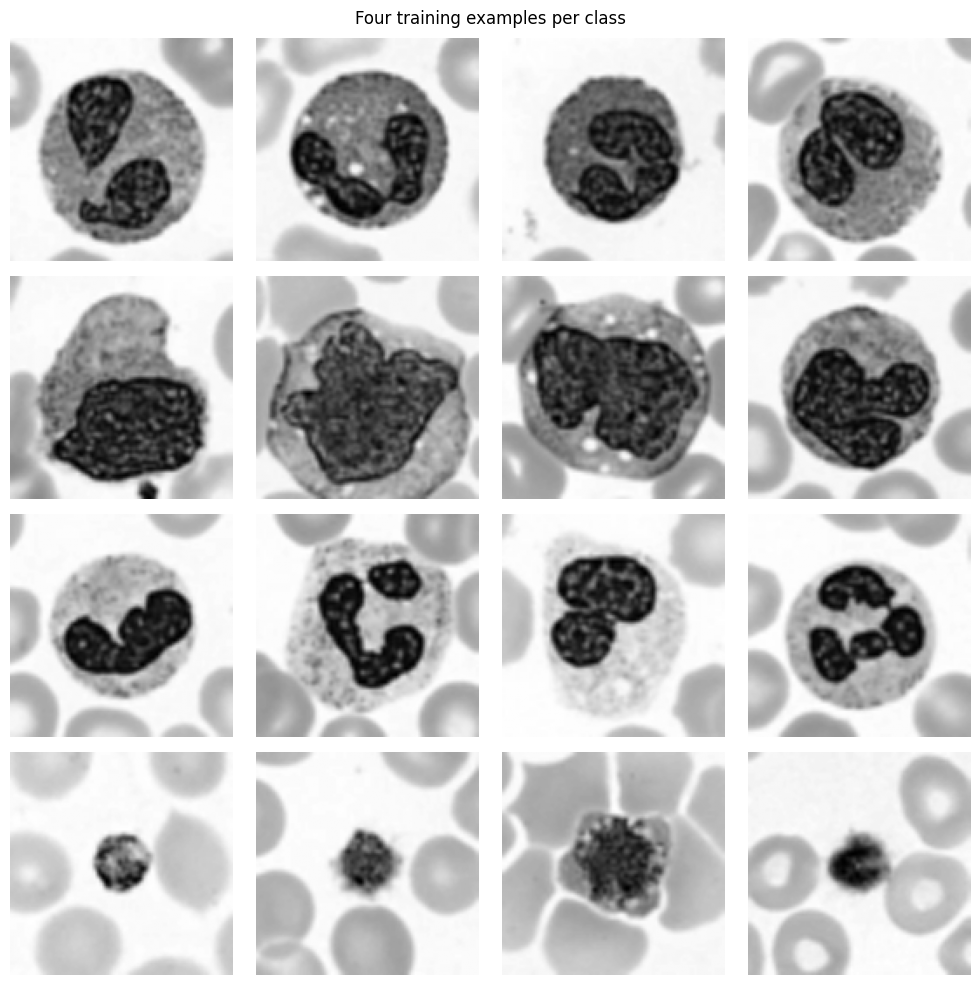

In [15]:
# Display 4 example images per class from the training subset
fig, axes = plt.subplots(len(CLASS_IDS), 4, figsize=(10, 10))
for row, class_id in enumerate(CLASS_IDS):
    inds = np.flatnonzero(train_y == class_id)[:4]
    for col, idx in enumerate(inds):
        axes[row, col].imshow(train_gray[idx], cmap="gray")
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_ylabel(CLASS_NAMES[class_id], rotation=90, size=10)
plt.suptitle("Four training examples per class")
plt.tight_layout()
plt.show()

## Q2. HOG + SVM (6 marks)

HOG settings from the brief: 9 orientations, 2 × 2 cells per block, and the cell size determined by your registration number.

**Feature-length calculation:** for a 128 × 128 image and cell size \(c 	imes c\), the number of cells per axis is \(128/c\). With 2 × 2 cells per block and one-cell block stride, blocks per axis are \((128/c)-1\). Each block contains \(2\times2\times9=36\) values, so the expected vector length is \(((128/c)-1)^2\times36\).

In [16]:
def extract_hog_one(gray):
    cell = HOG_CELL_SIZE
    feat, hog_image = hog(
        gray,
        orientations=9,
        pixels_per_cell=cell,
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        visualize=True,
        feature_vector=True
    )
    return feat.astype(np.float32), hog_image

X_train_hog, hog_visuals_train = [], []
for im in train_gray:
    feat, vis = extract_hog_one(im)
    X_train_hog.append(feat)
    hog_visuals_train.append(vis)
X_train_hog = np.vstack(X_train_hog)

X_val_hog = np.vstack([extract_hog_one(im)[0] for im in val_gray])
print("HOG feature matrix:", X_train_hog.shape)
print("HOG feature length:", X_train_hog.shape[1])
cells_per_axis = IMG_SIZE // HOG_CELL_SIZE[0]
manual_length = (cells_per_axis - 1) ** 2 * 2 * 2 * 9
print(f"Manual calculation: ({cells_per_axis} - 1)^2 blocks x (2 x 2 x 9) values = {manual_length}")
assert X_train_hog.shape[1] == manual_length, "Feature length differs from hand calculation; inspect settings."

HOG feature matrix: (400, 1764)
HOG feature length: 1764
Manual calculation: (8 - 1)^2 blocks x (2 x 2 x 9) values = 1764


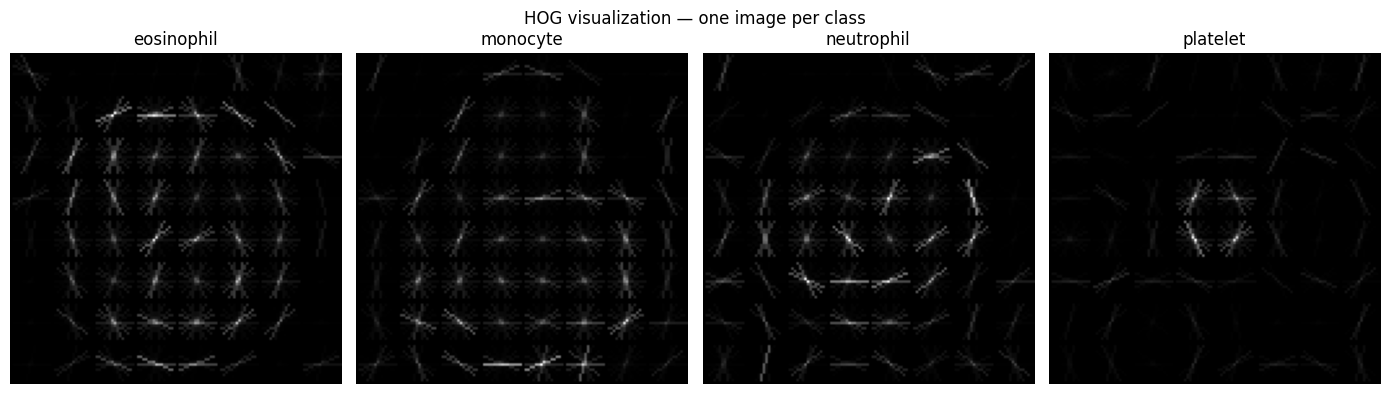

In [17]:
# Show one HOG visualization per class
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, class_id in zip(axes, CLASS_IDS):
    idx = np.flatnonzero(train_y == class_id)[0]
    _, vis = extract_hog_one(train_gray[idx])
    ax.imshow(vis, cmap="gray")
    ax.set_title(CLASS_NAMES[class_id])
    ax.axis("off")
plt.suptitle("HOG visualization — one image per class")
plt.tight_layout()
plt.show()

In [18]:
# Select C using validation only; test set is not used here.
C_VALUES = [0.1, 1, 10]
hog_validation_results = []
hog_models = {}
for c in C_VALUES:
    model = make_pipeline(StandardScaler(), LinearSVC(C=c, random_state=SEED, max_iter=20000))
    model.fit(X_train_hog, train_y)
    pred = model.predict(X_val_hog)
    acc = accuracy_score(val_y, pred)
    mf1 = f1_score(val_y, pred, average="macro", zero_division=0)
    hog_validation_results.append({"C": c, "validation_accuracy": acc, "validation_macro_f1": mf1})
    hog_models[c] = model

hog_validation_df = pd.DataFrame(hog_validation_results).sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False)
display(hog_validation_df)
best_hog_C = float(hog_validation_df.iloc[0]["C"])
best_hog_model = hog_models[best_hog_C]
hog_val_pred = best_hog_model.predict(X_val_hog)
print("Chosen HOG C:", best_hog_C)
print("Validation accuracy:", accuracy_score(val_y, hog_val_pred))
print("Validation macro-F1:", f1_score(val_y, hog_val_pred, average="macro", zero_division=0))
print("Validation confusion matrix (rows=true, columns=predicted; order =", [CLASS_NAMES[c] for c in CLASS_IDS], ")")
print(confusion_matrix(val_y, hog_val_pred, labels=CLASS_IDS))

,C,validation_accuracy,validation_macro_f1
0,0.1,0.708333,0.70936
1,1.0,0.708333,0.70936
2,10.0,0.708333,0.70936


Chosen HOG C: 0.1
Validation accuracy: 0.7083333333333334
Validation macro-F1: 0.7093604934112009
Validation confusion matrix (rows=true, columns=predicted; order = ['eosinophil', 'monocyte', 'neutrophil', 'platelet'] )
[[17  9  4  0]
 [ 7 21  2  0]
 [ 9  4 17  0]
 [ 0  0  0 30]]


## Q3. SIFT + SVM (7 marks)

First run normal SIFT detection on training images and report keypoint statistics. Then use a fixed regular grid so every image has a consistent descriptor length.

**Feature-length calculation:** each SIFT descriptor has 128 values. The fixed grid has \(g\times g\) points, so the concatenated feature length is \(g\times g\times128\).

Average keypoints per training image: 114.7975
Minimum keypoints: 12
Maximum keypoints: 321
Images with zero keypoints: 0


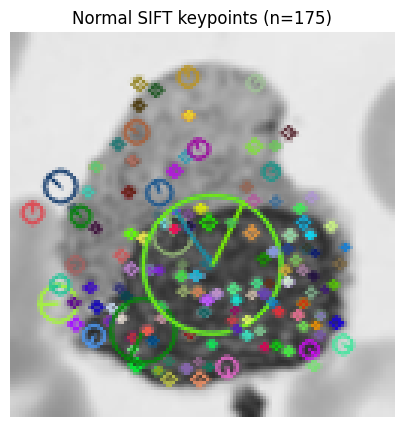

In [19]:
sift = cv2.SIFT_create()

normal_keypoint_counts = []
example_kp = None
example_img = None
for i, gray in enumerate(train_gray):
    keypoints, descriptors = sift.detectAndCompute(gray, None)
    normal_keypoint_counts.append(len(keypoints))
    if example_kp is None and len(keypoints) > 0:
        example_kp = keypoints
        example_img = gray

counts = np.asarray(normal_keypoint_counts)
print("Average keypoints per training image:", float(np.mean(counts)))
print("Minimum keypoints:", int(np.min(counts)))
print("Maximum keypoints:", int(np.max(counts)))
print("Images with zero keypoints:", int(np.sum(counts == 0)))

if example_kp is not None:
    drawn = cv2.drawKeypoints(example_img, example_kp, None,
                              flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.figure(figsize=(5, 5))
    plt.imshow(drawn, cmap="gray")
    plt.title(f"Normal SIFT keypoints (n={len(example_kp)})")
    plt.axis("off")
    plt.show()
else:
    print("No keypoints detected in any training image; cannot draw an example.")

**Why variable keypoint counts are a problem:** normal SIFT can return a different number of descriptors for each image, but a conventional SVM requires every sample to have the same fixed-length feature vector.

In [20]:
def fixed_grid_sift(gray, grid_size=SIFT_GRID_SIZE, keypoint_size=32):
    # Use a regular grid over the full 128 x 128 image.
    xs = np.linspace(0, IMG_SIZE - 1, grid_size + 2, dtype=np.float32)[1:-1]
    ys = np.linspace(0, IMG_SIZE - 1, grid_size + 2, dtype=np.float32)[1:-1]
    keypoints = [cv2.KeyPoint(float(x), float(y), float(keypoint_size))
                 for y in ys for x in xs]
    keypoints, descriptors = sift.compute(gray, keypoints)
    # SIFT may discard keypoints too close to boundaries. Keep a fixed-length vector
    # by zero-padding any missing descriptor rows, and preserve grid ordering as far as OpenCV returns it.
    expected_rows = grid_size * grid_size
    fixed = np.zeros((expected_rows, 128), dtype=np.float32)
    if descriptors is not None and len(descriptors) > 0:
        n = min(expected_rows, len(descriptors))
        fixed[:n] = descriptors[:n]
    return fixed.reshape(-1)

X_train_sift = np.vstack([fixed_grid_sift(im) for im in train_gray])
X_val_sift = np.vstack([fixed_grid_sift(im) for im in val_gray])
expected_sift_length = SIFT_GRID_SIZE * SIFT_GRID_SIZE * 128
print("SIFT feature matrix:", X_train_sift.shape)
print("SIFT feature length:", X_train_sift.shape[1])
print(f"Manual calculation: {SIFT_GRID_SIZE} x {SIFT_GRID_SIZE} grid points x 128 = {expected_sift_length}")
assert X_train_sift.shape[1] == expected_sift_length

SIFT feature matrix: (400, 4608)
SIFT feature length: 4608
Manual calculation: 6 x 6 grid points x 128 = 4608


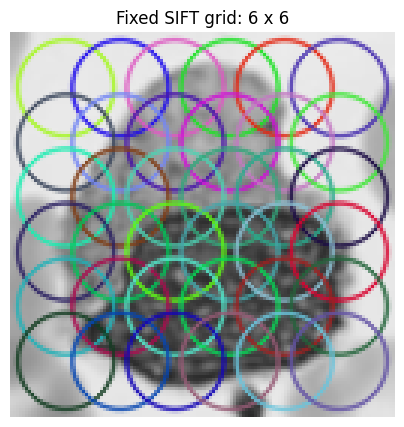

In [21]:
# Show the fixed grid keypoints and verify descriptor output
sample_idx = 0
gray = train_gray[sample_idx]
xs = np.linspace(0, IMG_SIZE - 1, SIFT_GRID_SIZE + 2, dtype=np.float32)[1:-1]
ys = np.linspace(0, IMG_SIZE - 1, SIFT_GRID_SIZE + 2, dtype=np.float32)[1:-1]
grid_kp = [cv2.KeyPoint(float(x), float(y), 32.0) for y in ys for x in xs]
grid_drawn = cv2.drawKeypoints(gray, grid_kp, None,
                               flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(grid_drawn, cmap="gray")
plt.title(f"Fixed SIFT grid: {SIFT_GRID_SIZE} x {SIFT_GRID_SIZE}")
plt.axis("off")
plt.show()

In [22]:
sift_validation_results = []
sift_models = {}
for c in C_VALUES:
    model = make_pipeline(StandardScaler(), LinearSVC(C=c, random_state=SEED, max_iter=20000))
    model.fit(X_train_sift, train_y)
    pred = model.predict(X_val_sift)
    acc = accuracy_score(val_y, pred)
    mf1 = f1_score(val_y, pred, average="macro", zero_division=0)
    sift_validation_results.append({"C": c, "validation_accuracy": acc, "validation_macro_f1": mf1})
    sift_models[c] = model

sift_validation_df = pd.DataFrame(sift_validation_results).sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False)
display(sift_validation_df)
best_sift_C = float(sift_validation_df.iloc[0]["C"])
best_sift_model = sift_models[best_sift_C]
sift_val_pred = best_sift_model.predict(X_val_sift)
print("Chosen SIFT C:", best_sift_C)
print("Validation accuracy:", accuracy_score(val_y, sift_val_pred))
print("Validation macro-F1:", f1_score(val_y, sift_val_pred, average="macro", zero_division=0))
print("Validation confusion matrix (rows=true, columns=predicted; order =", [CLASS_NAMES[c] for c in CLASS_IDS], ")")
print(confusion_matrix(val_y, sift_val_pred, labels=CLASS_IDS))

,C,validation_accuracy,validation_macro_f1
0,0.1,0.775,0.775192
1,1.0,0.775,0.775192
2,10.0,0.775,0.775192


Chosen SIFT C: 0.1
Validation accuracy: 0.775
Validation macro-F1: 0.7751920122887865
Validation confusion matrix (rows=true, columns=predicted; order = ['eosinophil', 'monocyte', 'neutrophil', 'platelet'] )
[[18  4  7  1]
 [ 8 22  0  0]
 [ 6  0 23  1]
 [ 0  0  0 30]]


## Q4. Robustness (6 marks)

**Prediction before running the robustness evaluation — edit this paragraph in your own words first.** Example hypothesis to consider: HOG may lose accuracy under rotation because its spatial gradient bins are orientation-sensitive; fixed-grid SIFT may be more tolerant to local orientation changes. Gaussian noise can disrupt local gradients and SIFT descriptors, so the outcome should be measured rather than assumed.

The models and C values selected on validation data are now frozen. The test set is used only in this section. Rotation is 20 degrees; Gaussian noise has sigma 0.05 after scaling pixel intensities to 0–1.

In [23]:
def rotate_gray(gray, angle=20):
    # Rotate around image center; keep same image dimensions.
    return rotate(gray, angle=angle, resize=False, mode="edge", preserve_range=True).astype(np.uint8)

def add_gaussian_noise(gray, sigma=0.05, seed=0):
    rng = np.random.default_rng(seed)
    img01 = gray.astype(np.float32) / 255.0
    noisy = np.clip(img01 + rng.normal(0.0, sigma, img01.shape), 0.0, 1.0)
    return np.round(noisy * 255).astype(np.uint8)

test_rotated = np.stack([rotate_gray(im, 20) for im in test_gray])
test_noisy = np.stack([add_gaussian_noise(im, 0.05, SEED + i) for i, im in enumerate(test_gray)])

# Extract test features only now, after the validation-selected models are frozen.
X_test_hog_clean = np.vstack([extract_hog_one(im)[0] for im in test_gray])
X_test_hog_rot = np.vstack([extract_hog_one(im)[0] for im in test_rotated])
X_test_hog_noise = np.vstack([extract_hog_one(im)[0] for im in test_noisy])

X_test_sift_clean = np.vstack([fixed_grid_sift(im) for im in test_gray])
X_test_sift_rot = np.vstack([fixed_grid_sift(im) for im in test_rotated])
X_test_sift_noise = np.vstack([fixed_grid_sift(im) for im in test_noisy])

robustness_rows = []
for model_name, model, features in [
    ("HOG + SVM", best_hog_model, [X_test_hog_clean, X_test_hog_rot, X_test_hog_noise]),
    ("SIFT + SVM", best_sift_model, [X_test_sift_clean, X_test_sift_rot, X_test_sift_noise])
]:
    scores = [accuracy_score(test_y, model.predict(x)) for x in features]
    robustness_rows.append({
        "Model": model_name,
        "Clean accuracy": scores[0],
        "Rotated accuracy": scores[1],
        "Noisy accuracy": scores[2]
    })

robustness_df = pd.DataFrame(robustness_rows)
display(robustness_df)
print("Use the actual values in this table to decide whether your prediction was correct.")

,Model,Clean accuracy,Rotated accuracy,Noisy accuracy
0,HOG + SVM,0.708333,0.700000,0.258333
1,SIFT + SVM,0.750000,0.716667,0.750000


Use the actual values in this table to decide whether your prediction was correct.


**Three-sentence interpretation template (complete after you see the table):**
1. On clean test images, ___ had accuracy ___, while ___ had accuracy ___.
2. After a 20° rotation, ___ changed from ___ to ___; this suggests ___ was more/less rotation-robust in this experiment.
3. Under Gaussian noise (sigma = 0.05), ___ changed from ___ to ___, so my prediction was ___ because ___.

## Q5. Short answers and AI log (3 marks)

### (a) Why does HOG use block normalisation?
HOG normalizes gradient histograms within local blocks to reduce sensitivity to overall illumination and contrast changes. Overlapping blocks also let local gradient patterns be represented in more than one normalized context.

### (b) Why is it wrong to choose C using the test set?
Choosing C based on test performance leaks information from the test set into model selection and makes the reported test score optimistically biased. The validation set is for model selection; the test set should be reserved for final evaluation.

### Which two classes did your models confuse most?
Run the cell below after Q4. Use the confusion matrices to identify the class pair with the largest off-diagonal errors. Grayscale can make classes harder to distinguish when color differences are informative, leaving only shape and texture cues.

In [24]:
# Confusion matrices on validation set (for the model-selection/reporting discussion)
print("HOG validation confusion matrix:")
print(confusion_matrix(val_y, best_hog_model.predict(X_val_hog), labels=CLASS_IDS))
print("SIFT validation confusion matrix:")
print(confusion_matrix(val_y, best_sift_model.predict(X_val_sift), labels=CLASS_IDS))
print("Class order:", [CLASS_NAMES[c] for c in CLASS_IDS])

def top_confused_pair(cm, class_ids=CLASS_IDS):
    cm = np.asarray(cm).copy()
    np.fill_diagonal(cm, 0)
    if cm.sum() == 0:
        return "No off-diagonal errors in this confusion matrix."
    i, j = np.unravel_index(np.argmax(cm), cm.shape)
    return f"Most frequent directed confusion: true {CLASS_NAMES[class_ids[i]]} predicted as {CLASS_NAMES[class_ids[j]]} ({cm[i, j]} cases)."

print(top_confused_pair(confusion_matrix(val_y, best_hog_model.predict(X_val_hog), labels=CLASS_IDS)))
print(top_confused_pair(confusion_matrix(val_y, best_sift_model.predict(X_val_sift), labels=CLASS_IDS)))

HOG validation confusion matrix:
[[17  9  4  0]
 [ 7 21  2  0]
 [ 9  4 17  0]
 [ 0  0  0 30]]
SIFT validation confusion matrix:
[[18  4  7  1]
 [ 8 22  0  0]
 [ 6  0 23  1]
 [ 0  0  0 30]]
Class order: ['eosinophil', 'monocyte', 'neutrophil', 'platelet']
Most frequent directed confusion: true eosinophil predicted as monocyte (9 cases).
Most frequent directed confusion: true monocyte predicted as eosinophil (8 cases).


### AI log (fill in honestly)
| Prompt (one line) | What I changed | How I checked correctness |
|---|---|---|
| Asked an AI assistant to help structure a HOG vs SIFT notebook from the lab brief. | I reviewed and edited the code for my registration settings and understanding. | Printed split shapes/counts, feature lengths, plots, validation metrics and robustness table. |

## Final checklist
- [ ] Replace the registration number.
- [ ] Run all cells in order and inspect errors.
- [ ] Check every printed value and plot; explain the main cells in your own words.
- [ ] Edit the Q4 prediction before running robustness.
- [ ] Write the interpretation using your actual outputs.
- [ ] Save as `RollNo_Name_LabMid.ipynb`, then export/download a PDF copy from Colab.
- [ ] Include visible outputs in the submitted notebook.